# Лабораторная работа 6. Mini-GPT с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Собрать полный декодер-трансформер из собственных модулей и экспериментально исследовать влияние архитектурных решений: места нормализации, типа нормализации и типа FFN.

**Что нужно сдать:**
1. Реализацию GPT: RMSNorm, attention с RoPE, SwiGLU, Pre/Post-LN, weight tying, масштабированная инициализация.
2. Сверку числа параметров и FLOPs с аналитическими формулами.
3. Обученную модель и журналы loss, норм градиентов и активаций по слоям.
4. Таблицу абляций: Pre-LN/Post-LN (с warmup и без), LayerNorm/RMSNorm, GELU/SwiGLU при равном числе параметров.
5. Сгенерированные тексты и сравнение perplexity с LSTM из ЛР 3.

Модель из этой работы используется в ЛР 7, 10, 11, 13 (в них для воспроизводимости подключается эталонная реализация).

**Теория. Подсчёт параметров.** Для \(L\) слоёв, ширины \(d\), словаря \(V\), без bias, с weight tying:
- attention: \(4d^2\) (матрицы \(W_Q, W_K, W_V, W_O\));
- FFN: \(8d^2\) (GELU со скрытым слоем \(4d\): \(2 \cdot 4d^2\); SwiGLU со скрытым слоем \(\tfrac{8}{3}d\): \(3 \cdot \tfrac{8}{3}d^2\));
- нормализации: \(2d\) на слой (RMSNorm) или \(4d\) (LayerNorm с bias), плюс финальная;
- эмбеддинги: \(Vd\).

Итого \(N \approx 12Ld^2 + Vd\). Прямой проход стоит \(\approx 2N_{\text{non-emb}} + 2LTd\) FLOPs на токен (второй член — \(QK^\top\) и \(PV\) при длине контекста \(T\), с учётом каузальной маски в среднем вдвое меньше).

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.6.0+cpu, device=cpu, FAST_DEV_RUN=True


## 0. Данные

В режиме `FAST_DEV_RUN` используется Tiny Shakespeare, в полном режиме — валидационная часть TinyStories (около 22 МБ). Токенизация символьная; по желанию можно подключить BPE из ЛР 1 (дополнительное задание).

In [2]:
if FAST_DEV_RUN:
    text = load_shakespeare()
else:
    text = download("https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStoriesV2-GPT4-valid.txt",
                    "tinystories_valid.txt").read_text(encoding="utf-8")
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; V = len(chars)
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
data = torch.tensor(encode(text)); ntr = int(0.9 * len(data)); train_data, val_data = data[:ntr], data[ntr:]
print(f"символов: {len(data):,}, |V| = {V}")

символов: 1,115,394, |V| = 65


## 1. Модули

In [3]:
from dataclasses import dataclass, replace

@dataclass
class Config:
    vocab_size: int = V
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    norm: str = "rms"        # "rms" | "ln"
    norm_pos: str = "pre"    # "pre" | "post"
    mlp: str = "swiglu"      # "swiglu" | "gelu"
    tie_weights: bool = True

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(d))
    def forward(self, x):
        # TODO: ваш код
        # Нормируем RMS, не вычитая среднее и не добавляя bias.
        return x * torch.rsqrt(x.square().mean(-1, keepdim=True) + self.eps) * self.weight

def make_norm(cfg): return RMSNorm(cfg.n_embd) if cfg.norm == "rms" else nn.LayerNorm(cfg.n_embd)

def rope_cache(T, d_head, base=10000.0):
    inv = base ** (-torch.arange(0, d_head, 2).float() / d_head)
    ang = torch.outer(torch.arange(T).float(), inv)
    return ang.cos(), ang.sin()

def apply_rope(x, cos, sin):
    # TODO: ваш код
    T = x.size(-2)
    c, s = cos[:T].to(x), sin[:T].to(x)
    a, b = x[..., 0::2], x[..., 1::2]
    return torch.stack((a * c - b * s, a * s + b * c), dim=-1).flatten(-2)

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.h, self.dh = cfg.n_head, cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
    def forward(self, x, cos, sin):
        B, T, C = x.shape
        # TODO: ваш код (q, k, v → (B, H, T, dh); RoPE для q и k; собственная или F.scaled_dot_product_attention с is_causal)
        q, k, v = (t.reshape(B, T, self.h, self.dh).transpose(1, 2)
                   for t in self.qkv(x).split(C, dim=-1))
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.dh)
        future = torch.ones(T, T, dtype=torch.bool, device=x.device).triu(1)
        p = scores.masked_fill(future, -torch.inf).softmax(-1)
        y = p @ v
        return self.proj(y.transpose(1, 2).reshape(B, T, C))

class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__(); d = cfg.n_embd; self.kind = cfg.mlp
        if cfg.mlp == "swiglu":
            hidden = int(8 * d / 3)
            self.w1, self.w3, self.w2 = nn.Linear(d, hidden, bias=False), nn.Linear(d, hidden, bias=False), nn.Linear(hidden, d, bias=False)
        else:
            self.w1, self.w2 = nn.Linear(d, 4 * d, bias=False), nn.Linear(4 * d, d, bias=False)
    def forward(self, x):
        # TODO: ваш код
        if self.kind == "swiglu":
            return self.w2(F.silu(self.w1(x)) * self.w3(x))
        return self.w2(F.gelu(self.w1(x)))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__(); self.pos = cfg.norm_pos
        self.n1, self.attn, self.n2, self.mlp = make_norm(cfg), CausalSelfAttention(cfg), make_norm(cfg), MLP(cfg)
    def forward(self, x, cos, sin):
        # TODO: ваш код (Pre-LN: x + f(norm(x)); Post-LN: norm(x + f(x)))
        if self.pos == "pre":
            x = x + self.attn(self.n1(x), cos, sin)
            return x + self.mlp(self.n2(x))
        x = self.n1(x + self.attn(x, cos, sin))
        return self.n2(x + self.mlp(x))

class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__(); self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm_f = make_norm(cfg) if cfg.norm_pos == "pre" else nn.Identity()
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        if cfg.tie_weights: self.head.weight = self.wte.weight
        cos, sin = rope_cache(cfg.block_size, cfg.n_embd // cfg.n_head)
        self.register_buffer("cos", cos, persistent=False); self.register_buffer("sin", sin, persistent=False)
        # TODO: ваш код (N(0, 0.02) для всех Linear/Embedding, выходные проекции proj и w2 — 0.02/sqrt(2L))
        initialized = set()
        for module in self.modules():
            if isinstance(module, (nn.Linear, nn.Embedding)):
                # При tying общая матрица инициализируется один раз.
                if id(module.weight) not in initialized:
                    nn.init.normal_(module.weight, 0.0, 0.02)
                    initialized.add(id(module.weight))
                if isinstance(module, nn.Linear) and module.bias is not None:
                    nn.init.zeros_(module.bias)
        for block in self.blocks:
            for projection in (block.attn.proj, block.mlp.w2):
                nn.init.normal_(projection.weight, 0.0, 0.02 / math.sqrt(2 * cfg.n_layer))
    def forward(self, idx, targets=None, return_hidden=False):
        x = self.wte(idx); hidden = [x]
        for b in self.blocks:
            x = b(x, self.cos, self.sin); hidden.append(x)
        logits = self.head(self.norm_f(x))
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return (logits, loss, hidden) if return_hidden else (logits, loss)
    @torch.no_grad()
    def generate(self, idx, n, temperature=1.0, top_k=None):
        for _ in range(n):
            logits = self(idx[:, -self.cfg.block_size:])[0][:, -1] / temperature
            if top_k: logits[logits < logits.topk(top_k).values[:, -1:]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(logits.softmax(-1), 1)], 1)
        return idx

## 2. Число параметров и FLOPs

Реализуйте аналитические формулы и сверьте их с фактическим числом параметров для нескольких конфигураций. Измерьте FLOPs прямого прохода профайлером `torch.utils.flop_counter.FlopCounterMode` и сравните с формулой \(2N_{\text{non-emb}} + 2LTd\) на токен (плюс \(2Vd\) на выходную голову).

In [4]:
def analytic_params(cfg):
    # TODO: ваш код
    d, L, V = cfg.n_embd, cfg.n_layer, cfg.vocab_size
    ffn = 3 * d * int(8 * d / 3) if cfg.mlp == "swiglu" else 8 * d * d
    norm = d if cfg.norm == "rms" else 2 * d
    return L * (4 * d * d + ffn + 2 * norm) + (norm if cfg.norm_pos == "pre" else 0) + V * d * (1 if cfg.tie_weights else 2)

def analytic_forward_flops(cfg, T):
    """FLOPs прямого прохода на всю последовательность длины T (умножение+сложение = 2 FLOP)."""
    # TODO: ваш код
    d, L, V = cfg.n_embd, cfg.n_layer, cfg.vocab_size
    ffn = 3 * d * int(8 * d / 3) if cfg.mlp == "swiglu" else 8 * d * d
    # Идеальная каузальная реализация: только T*(T+1)/2 пар в каждом матмуле.
    return 2 * T * (L * (4*d*d + ffn) + V*d) + 2*L*T*(T+1)*d

def dense_forward_flops(cfg, T):
    # В нашей реализации QK^T и PV — полные матрицы, несмотря на маску.
    return analytic_forward_flops(cfg, T) - 2*cfg.n_layer*T*(T+1)*cfg.n_embd + 4*cfg.n_layer*T*T*cfg.n_embd

print("Первая формула — идеальная треугольная каузальность; профайлер видит dense-матмулы.")
print("Нормы, softmax, RoPE и активации в этой оценке не учитываются.")

from torch.utils.flop_counter import FlopCounterMode
for cfg in [Config(), Config(n_layer=6, n_embd=192, n_head=6, mlp="gelu"), Config(norm="ln", tie_weights=False)]:
    m = GPT(cfg); x = torch.randint(V, (1, cfg.block_size))
    fc = FlopCounterMode(display=False)
    with fc, torch.no_grad(): m(x)
    print(f"L={cfg.n_layer} d={cfg.n_embd} {cfg.mlp:6s} {cfg.norm}: params={sum(p.numel() for p in m.parameters()):,} "
          f"(формула {analytic_params(cfg):,}); FLOPs={fc.get_total_flops():.3e} (формула {analytic_forward_flops(cfg, cfg.block_size):.3e})")
    assert sum(p.numel() for p in m.parameters()) == analytic_params(cfg)
    dense = dense_forward_flops(cfg, cfg.block_size)
    print(f"  dense-формула={dense:.3e}; разница с профайлером={abs(fc.get_total_flops() - dense) / dense:.2%}")

Первая формула — идеальная треугольная каузальность; профайлер видит dense-матмулы.
Нормы, softmax, RoPE и активации в этой оценке не учитываются.
L=4 d=128 swiglu rms: params=795,392 (формула 795,392); FLOPs=2.369e+08 (формула 2.202e+08)
  dense-формула=2.369e+08; разница с профайлером=0.00%
L=6 d=192 gelu   rms: params=2,669,184 (формула 2,669,184); FLOPs=7.582e+08 (формула 7.207e+08)
  dense-формула=7.582e+08; разница с профайлером=0.00%


L=4 d=128 swiglu ln: params=804,864 (формула 804,864); FLOPs=2.369e+08 (формула 2.202e+08)
  dense-формула=2.369e+08; разница с профайлером=0.00%


## 3. Обучение с журналом диагностик

Логируйте каждые `LOG_EVERY` шагов:
- loss на обучении и валидации;
- норму градиента по каждому блоку;
- RMS активаций residual stream после каждого блока.

In [5]:
def get_batch(d, T, B):
    ix = torch.randint(len(d) - T - 1, (B,))
    return torch.stack([d[i:i + T] for i in ix]).to(DEVICE), torch.stack([d[i + 1:i + T + 1] for i in ix]).to(DEVICE)

@torch.no_grad()
def eval_loss(model, d, iters=20, B=32):
    model.eval(); l = np.mean([model(*get_batch(d, model.cfg.block_size, B))[1].item() for _ in range(iters)]); model.train(); return l

def train(cfg, steps, lr=3e-3, warmup=100, B=32, log_every=50, seed=SEED):
    set_seed(seed); model = GPT(cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    # TODO: ваш код (линейный warmup + косинусное затухание (LambdaLR); clip_grad_norm_(1.0); журнал диагностик)
    def lr_factor(step):
        if warmup and step < warmup:
            return (step + 1) / warmup
        progress = min(max((step - warmup) / max(1, steps - warmup), 0.0), 1.0)
        return 0.5 * (1 + math.cos(math.pi * progress))
    scheduler = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda=lr_factor)
    log = {k: [] for k in ("step", "train", "val", "grad", "act", "lr", "total_grad")}
    log.update(diverged=False, steps_completed=0)
    # Архитектуры расходуют разное число случайных чисел при инициализации.
    # Сбрасываем поток батчей, чтобы окна при абляциях совпадали.
    torch.manual_seed(seed + 1)
    for step in range(steps):
        model.train(); x, y = get_batch(train_data, cfg.block_size, B)
        opt.zero_grad(set_to_none=True)
        _, loss, hidden = model(x, y, return_hidden=True)
        if not torch.isfinite(loss):
            log["diverged"] = True; break
        loss.backward()
        grads = [math.sqrt(sum(p.grad.detach().double().square().sum().item()
                               for p in block.parameters() if p.grad is not None)) for block in model.blocks]
        total_grad = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0).item()
        if not math.isfinite(total_grad):
            log["diverged"] = True; break
        current_lr = opt.param_groups[0]["lr"]
        opt.step(); scheduler.step(); log["steps_completed"] = step + 1
        if step < 5 or (step + 1) % log_every == 0 or step == steps - 1:
            acts = [h.detach().double().square().mean().sqrt().item() for h in hidden]
            # Оценка на одних окнах и без влияния на RNG обучающих батчей.
            devices = [torch.cuda.current_device()] if DEVICE == "cuda" else []
            with torch.random.fork_rng(devices=devices):
                torch.manual_seed(seed + 2)
                validation = eval_loss(model, val_data, B=B)
            for key, value in [("step", step + 1), ("train", loss.item()), ("val", float(validation)),
                               ("grad", grads), ("act", acts), ("lr", current_lr), ("total_grad", total_grad)]:
                log[key].append(value)
            if (step + 1) % log_every == 0 or step == steps - 1:
                print(f"шаг {step + 1}/{steps}: train={loss.item():.3f}, val={validation:.3f}, grad до clipping={total_grad:.3f}")
    return model, log

STEPS = 300 if FAST_DEV_RUN else 5000
base_cfg = Config(block_size=128 if FAST_DEV_RUN else 256, n_layer=4 if FAST_DEV_RUN else 6,
                  n_embd=128 if FAST_DEV_RUN else 384, n_head=4 if FAST_DEV_RUN else 6)
t0 = time.time(); model, log = train(base_cfg, STEPS)
print(f"{time.time() - t0:.0f} c; параметров {sum(p.numel() for p in model.parameters()):,}; val loss {log['val'][-1]:.3f}")
torch.save({"cfg": base_cfg.__dict__, "state": model.state_dict(), "chars": chars}, ARTIFACTS / "lab06_gpt.pt")

шаг 50/300: train=2.534, val=2.546, grad до clipping=0.630


шаг 100/300: train=2.114, val=2.150, grad до clipping=0.671


шаг 150/300: train=1.953, val=2.025, grad до clipping=0.690


шаг 200/300: train=1.805, val=1.903, grad до clipping=0.608


шаг 250/300: train=1.652, val=1.827, grad до clipping=0.526


шаг 300/300: train=1.636, val=1.795, grad до clipping=0.504
124 c; параметров 795,392; val loss 1.795


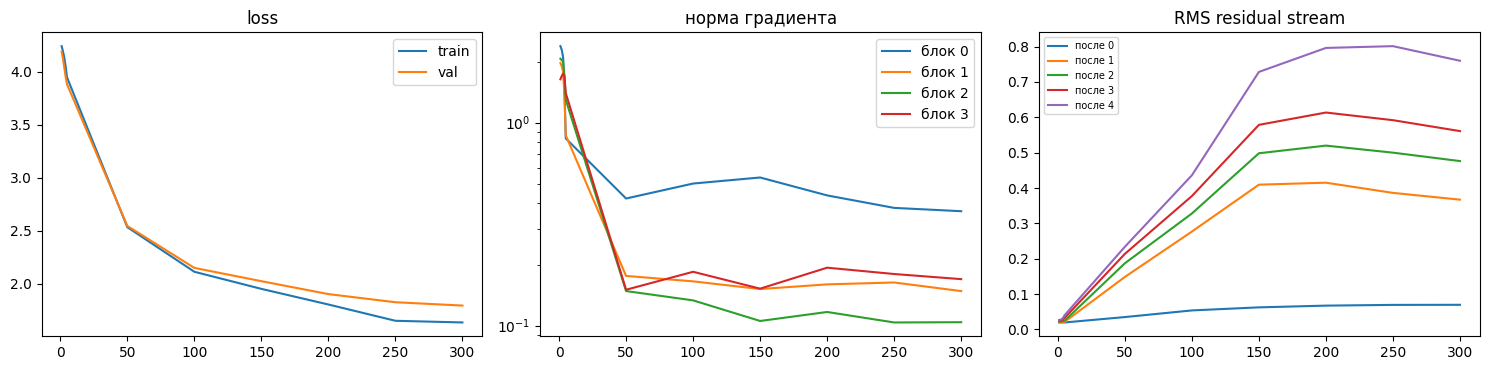

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(log["step"], log["train"], label="train"); ax[0].plot(log["step"], log["val"], label="val"); ax[0].legend(); ax[0].set_title("loss")
g = np.array(log["grad"]); [ax[1].plot(log["step"], g[:, i], label=f"блок {i}") for i in range(g.shape[1])]; ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("норма градиента")
a = np.array(log["act"]); [ax[2].plot(log["step"], a[:, i], label=f"после {i}") for i in range(a.shape[1])]; ax[2].legend(fontsize=7); ax[2].set_title("RMS residual stream")
plt.tight_layout(); plt.show()

## 4. Абляции

Обучите при одинаковом бюджете шагов:

| Вариант | Изменение относительно базового |
|---|---|
| base | Pre-RMSNorm, SwiGLU, warmup (10% шагов) |
| post-ln | Post-norm, warmup |
| post-ln, без warmup | Post-norm, warmup 0 |
| pre-ln, без warmup | Pre-norm, warmup 0 |
| layernorm | LayerNorm вместо RMSNorm |
| gelu | GELU-FFN (4d) вместо SwiGLU (8d/3) |

Используйте два значения learning rate (3e-3 и 1e-2; в `FAST_DEV_RUN` только 1e-2), чтобы выявить неустойчивость. Сравните итоговый val loss, долю «взорвавшихся» запусков и нормы градиентов по слоям в начале обучения.


base: lr=0.01, warmup=15/150


шаг 50/150: train=2.615, val=2.571, grad до clipping=0.524


шаг 100/150: train=2.333, val=2.371, grad до clipping=0.316


шаг 150/150: train=2.299, val=2.316, grad до clipping=0.320

post-ln: lr=0.01, warmup=15/150


шаг 50/150: train=3.341, val=3.349, grad до clipping=0.387


шаг 100/150: train=3.344, val=3.342, grad до clipping=0.248


... (12 outputs left out)

шаг 150/150: train=2.273, val=2.308, grad до clipping=0.288


,вариант,lr,norm,norm_pos,FFN,warmup,параметров,шагов,val CE,нечисловой loss/grad,grad первого шага
0,base,0.01,rms,pre,swiglu,15,795392,150,2.3160,False,4.4879
1,post-ln,0.01,rms,post,swiglu,15,795264,150,3.3413,False,1.4114
2,"post-ln, без warmup",0.01,rms,post,swiglu,0,795264,150,3.3416,False,1.4114
3,"pre-ln, без warmup",0.01,rms,pre,swiglu,0,795392,150,2.6330,False,4.4879
4,layernorm,0.01,ln,pre,swiglu,15,796544,150,2.3618,False,4.4404
5,gelu,0.01,rms,pre,gelu,15,795904,150,2.3085,False,5.5729


Доля запусков с нечисловым loss/grad:


lr
0.01    0.0
Name: нечисловой loss/grad, dtype: float64

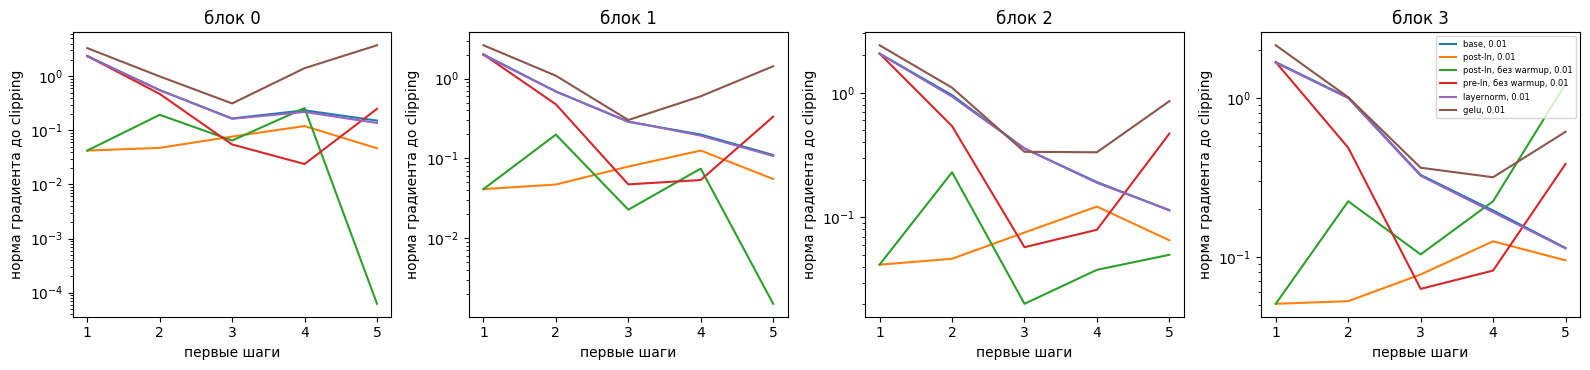

In [7]:
ABL_STEPS = 150 if FAST_DEV_RUN else 3000
ABL_LRS = (1e-2,) if FAST_DEV_RUN else (3e-3, 1e-2)
abl_cfg = replace(base_cfg, block_size=64) if FAST_DEV_RUN else base_cfg
variants = {
    "base": (abl_cfg, 30), "post-ln": (replace(abl_cfg, norm_pos="post"), 30),
    "post-ln, без warmup": (replace(abl_cfg, norm_pos="post"), 0), "pre-ln, без warmup": (abl_cfg, 0),
    "layernorm": (replace(abl_cfg, norm="ln"), 30), "gelu": (replace(abl_cfg, mlp="gelu"), 30),
}
# TODO: ваш код (обучите все варианты при lr из {3e-3, 1e-2}, соберите таблицу и графики норм градиентов на первых шагах)

# В шаблоне 30/150 = 20%, а текст задания просит 10% warmup.
variants = {name: (cfg, max(1, round(0.1 * ABL_STEPS)) if warm else 0)
            for name, (cfg, warm) in variants.items()}
abl_runs, rows = {}, []
for lr in ABL_LRS:
    for name, (cfg, warmup) in variants.items():
        print(f"\n{name}: lr={lr:g}, warmup={warmup}/{ABL_STEPS}")
        candidate, history = train(cfg, ABL_STEPS, lr=lr, warmup=warmup)
        abl_runs[(name, lr)] = history
        ce = history["val"][-1] if history["val"] and not history["diverged"] else float("nan")
        rows.append({"вариант": name, "lr": lr, "norm": cfg.norm, "norm_pos": cfg.norm_pos,
                     "FFN": cfg.mlp, "warmup": warmup, "параметров": analytic_params(cfg),
                     "шагов": history["steps_completed"], "val CE": ce,
                     "нечисловой loss/grad": history["diverged"],
                     "grad первого шага": history["total_grad"][0] if history["total_grad"] else float("nan")})
import pandas as pd
ablation_df = pd.DataFrame(rows)
display(ablation_df.round(4))
print("Доля запусков с нечисловым loss/grad:")
display(ablation_df.groupby("lr")["нечисловой loss/grad"].mean())
fig, axes = plt.subplots(1, abl_cfg.n_layer, figsize=(4*abl_cfg.n_layer, 3.8), squeeze=False)
for (name, lr), history in abl_runs.items():
    early = np.asarray(history["step"]) <= 5
    grads = np.asarray(history["grad"])
    for layer, ax in enumerate(axes[0]):
        if len(grads): ax.plot(np.asarray(history["step"])[early], grads[early, layer], label=f"{name}, {lr:g}")
        ax.set_xlabel("первые шаги"); ax.set_ylabel("норма градиента до clipping")
        ax.set_title(f"блок {layer}"); ax.set_yscale("log")
axes[0, -1].legend(fontsize=6); plt.tight_layout(); plt.show()
# post-ln/pre-ln в шаблоне меняют место нормы, но её тип остаётся rms.
# int(8*d/3) выравнивает FFN-бюджет приближённо; точные параметры указаны в таблице.


## 5. Генерация и сравнение с LSTM

Сгенерируйте тексты при разных температурах и top-k. Посчитайте perplexity и bits-per-character на валидации и сравните с LSTM из ЛР 3 (для Shakespeare при коротком обучении LSTM давала около 2.5 бит/символ).

In [8]:
val_ce = eval_loss(model, val_data, iters=50)
print(f"GPT: CE={val_ce:.3f} нат, perplexity={math.exp(val_ce):.2f}, bpc={val_ce / math.log(2):.3f}")
for t, k in [(0.5, None), (1.0, None), (1.0, 10)]:
    out = model.generate(torch.tensor([encode("ROMEO:" if FAST_DEV_RUN else "Once upon a time")], device=DEVICE), 300, t, k)
    print(f"\n--- T={t}, top_k={k}\n{decode(out[0].tolist())}")

# Из выполненной ЛР3: LSTM 2.509 бит/символ. Там оценивались первые 20000
# символов val с переносом состояния, здесь — случайные окна block_size.
# Архитектуры, контекст и протоколы различны: сравнение ориентировочное.
lstm_bpc = 2.509
display(pd.DataFrame([
    {"модель": "GPT, текущая оценка", "CE (нат)": val_ce, "perplexity": math.exp(val_ce), "бит/символ": val_ce/math.log(2)},
    {"модель": "LSTM, результат ЛР3", "CE (нат)": lstm_bpc*math.log(2), "perplexity": 2**lstm_bpc, "бит/символ": lstm_bpc},
]).round(4))
flop_rows = []
for T in (128, 8192):
    flop_rows.append({"T": T, "доля attention, dense": 4*base_cfg.n_layer*T*T*base_cfg.n_embd/dense_forward_flops(base_cfg,T),
                      "доля attention, ideal causal": 2*base_cfg.n_layer*T*(T+1)*base_cfg.n_embd/analytic_forward_flops(base_cfg,T)})
display(pd.DataFrame(flop_rows).round(4))
d = base_cfg.n_embd
ffn = 3*d*int(8*d/3) if base_cfg.mlp == "swiglu" else 8*d*d
linear_weights = base_cfg.n_layer*(4*d*d + ffn) + base_cfg.vocab_size*d
print(f"Матмулы attention превосходят линейные: dense T > {linear_weights/(2*base_cfg.n_layer*d):.1f}; "
      f"идеальная каузальность T > {linear_weights/(base_cfg.n_layer*d)-1:.1f}")


GPT: CE=1.794 нат, perplexity=6.01, bpc=2.588



--- T=0.5, top_k=None
ROMEO:
What a do be what good bether deal and their that
That the your a king him not in him come.

AUTOLYCUS:
He shall the with he with a the soul to the with a with you thee.

LUCIO:
Which it the such say I brother sand be to it.

Second Sentry the comes cannothing the compere home,
The courtune to your



--- T=1.0, top_k=None
ROMEO:
Which, thou that your a lad's to the cusackly thined you
e speak!
Sto not hou foul her the your limand,
Look I kinous havemaken; eak to grah'cut you.
Is war. Anooth! I day, mell; what you, who pertor.

CORIOLANUS:
Frose, be he me; match this lavel some ebak-leiars
And you bleased I 'ears. Thumbrawd



--- T=1.0, top_k=10
ROMEO:
Ye and take more of this forth.

MENENIUS:
In made which or the chirded's of the done.
You bust to by hing, with more for thank,
As this my hastains brother of may frion.

LEORTES:
I will now, and my boths where you
O shall but thouse, to bind, which the will was tanded,
So make nriture the honour,


,модель,CE (нат),perplexity,бит/символ
0,"GPT, текущая оценка",1.7938,6.0122,2.5879
1,"LSTM, результат ЛР3",1.7391,5.6923,2.5090


,T,"доля attention, dense","доля attention, ideal causal"
0,128,0.1417,0.0768
1,8192,0.9135,0.8408


Матмулы attention превосходят линейные: dense T > 775.6; идеальная каузальность T > 1550.2


## Вопросы

1. Почему Post-LN требует warmup, а Pre-LN обучается и без него? Свяжите ответ с нормами градиентов по слоям при инициализации (Xiong et al., 2020).

   Post-norm включает якобиан нормализации в обратный путь каждого residual-блока. При инициализации градиенты могут быть неравномерны и велики ближе к выходу; warmup ограничивает первые обновления. У Pre-norm остаётся прямой путь с единичной производной, что обычно облегчает старт. Это тенденция, а не запрет Post-norm без warmup. Наш вариант post-ln сохраняет RMSNorm базовой конфигурации, поэтому не воспроизводит все условия статьи Xiong et al. В коротком прогоне Post-RMSNorm дал val CE около 3.341 и с warmup, и без него; Pre-RMSNorm с warmup — 2.316. Нечисловых loss/grad не было ни в одном из шести запусков. Это не доказывает устойчивость при любой глубине и learning rate.
2. Зачем выходные проекции инициализируются с множителем \(1/\sqrt{2L}\)? Что происходит с дисперсией residual stream без этого множителя?

   Две residual-ветви в каждом блоке добавляют сигнал. При примерно независимых вкладах суммарная дисперсия без масштабирования растёт с 2L. Множитель 1/sqrt(2L) уменьшает дисперсию каждого вклада в 2L раз. Корреляции и нелинейности делают это оценкой, а не точным равенством.
3. Почему у SwiGLU скрытый размер \(\tfrac{8}{3}d\)? Какое свойство сравнения это обеспечивает?

   GELU имеет 2*d*(4d)=8d^2 весов FFN, SwiGLU — 3*d*hidden. При hidden=8d/3 бюджеты совпадают в ведущем порядке. Из-за округления при d=128 hidden=341; SwiGLU имеет на 128 весов меньше на блок, то есть на 512 для 4 блоков. Точные числа видны в таблице.
4. Что даёт weight tying и почему оно естественно для языковой модели?

   Weight tying связывает выходную матрицу с тем же Parameter, что и входной embedding, экономя V*d весов. Входные и выходные символы используют один словарь, поэтому совместное представление естественно. Гарантии улучшения качества для любой задачи из этого не следует.
5. Какая доля FLOPs приходится на attention при \(T = 128\) и при \(T = 8192\) для вашей конфигурации? При каком \(T\) attention начинает доминировать?

   При T=128 на attention-матмулы приходится 14.17% dense FLOPs, при T=8192 — 91.35%; для идеальной каузальной реализации это 7.68% и 84.08%. Attention начинает превосходить остальные матмулы при T больше примерно 775.6 для dense или 1550.2 для идеальной каузальности. Attention здесь означает два матмула QK^T и PV: dense даёт 4*L*T^2*d, идеальная каузальность —2*L*T*(T+1)*d. Линейные проекции и голова растут только как T, поэтому на длинном контексте attention доминирует. Профайлер нашей реализации считает полные матрицы, а треугольная формула описывает потенциальную экономию.
